# Global carbonate system: results

goSPL's carbonate module on the 250 Ma (Pangea) mesh of `continental_flux`,
1 Myr, focused on the tropical carbonate: reef builders, platform and deeper
producers limited to warm water by the sea-surface temperature, pelagic carbonate above the CCD, hemipelagic clay, waves and
coastal erosion, and the coupling with the continental geochemistry. The runs
are described in `README.md` and in the header of each `input-*.yml`. The
plotting functions are in `scripts/globalcarb.py`.

In [1]:
import sys
sys.path.insert(0, 'scripts')
import matplotlib.pyplot as plt
import globalcarb as G

## The forcing

The sea-surface temperature map (warm tropics, cold poles) limits the three
tropical factories to warm water (full growth from about 18-20 to 28-30 degC) and lowers the pelagic carbonate rain in
cold water; the pelagic carbonate rain (before dissolution) is highest under
the tropical belt. Replace these maps (`data/carb_maps.npz`) with
climate-model fields for a real study.

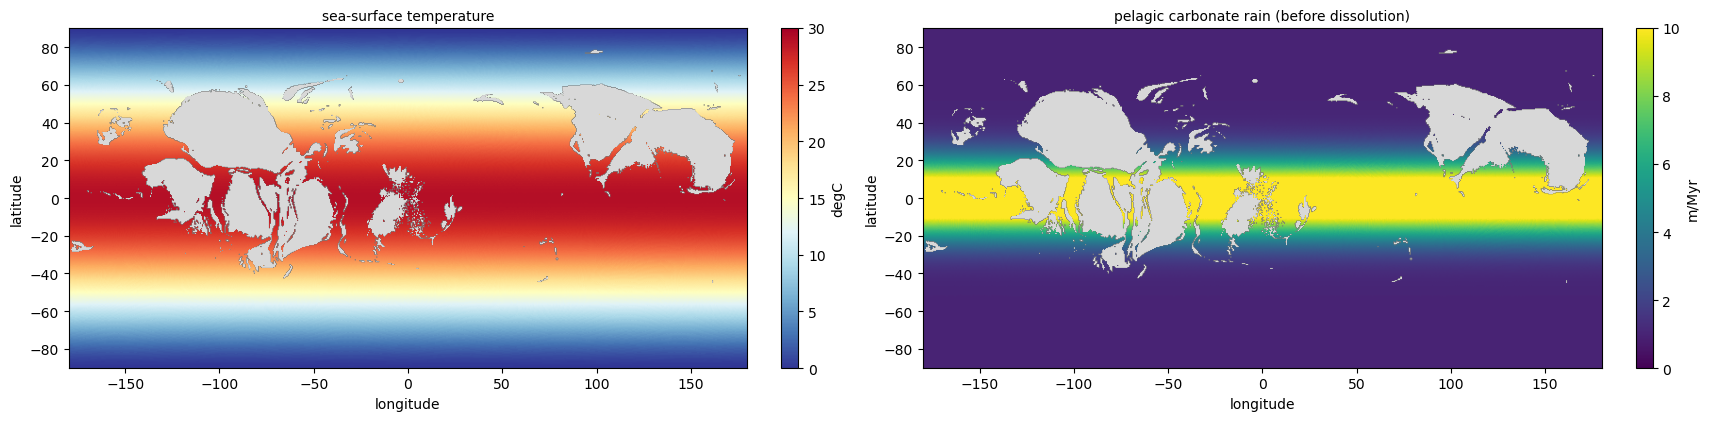

In [2]:
G.forcing();

## The reference (`input-carb.yml`)

Benthic carbonate grows on the tropical shelves and margins (Tethys, the
Pangea coasts within the warm belt), a few cells wide at this resolution.
Pelagic carbonate covers the tropical belt where the seafloor lies above
the CCD (4500 m) and fades with depth below the lysocline (3500 m);
hemipelagic clay lines the continents. Over 1 Myr: 2.23 million km3 of
benthic carbonate (0.28 as reef framework), 1.28 million km3 of pelagic
carbonate preserved and 0.35 dissolved; 77 % of the carbonate lies in the
tropics.

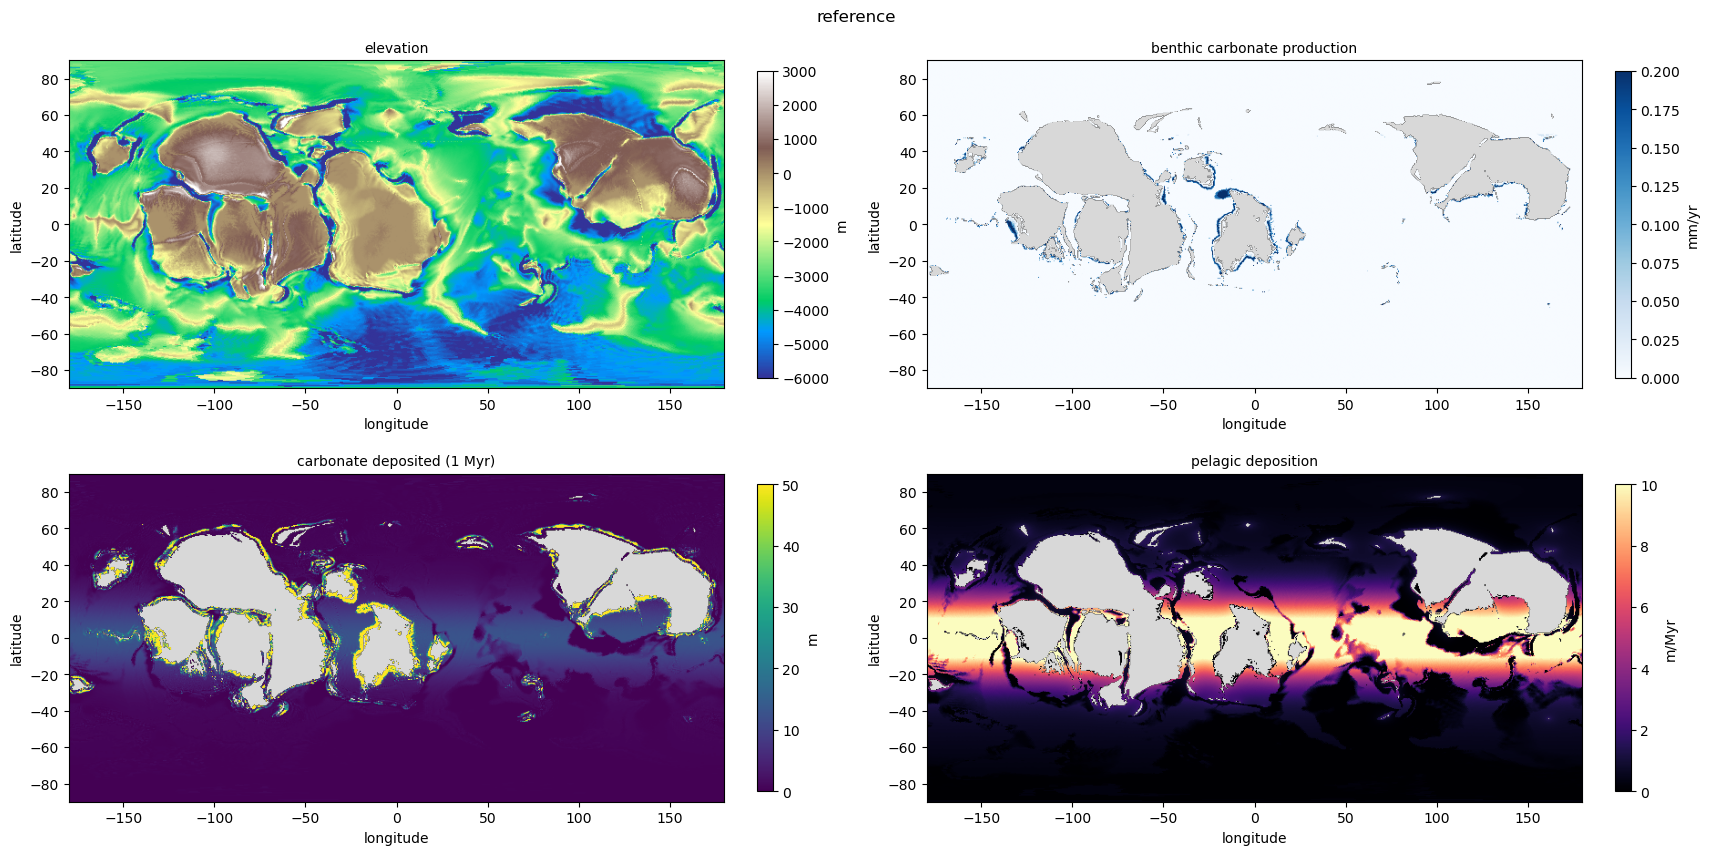

In [3]:
G.overview('sim_carb', 'reference');

## The CCD (`input-ccd_shallow.yml`)

With the lysocline at 2500 m and the CCD at 3500 m instead of 3500 and
4500 m, the pelagic carbonate kept in the basins falls by 31 % (0.89 million
km3 against 1.28) and the dissolved part doubles (0.74 against 0.35): the
tropical belt breaks up over the deep basins. The benthic carbonate does
not change.

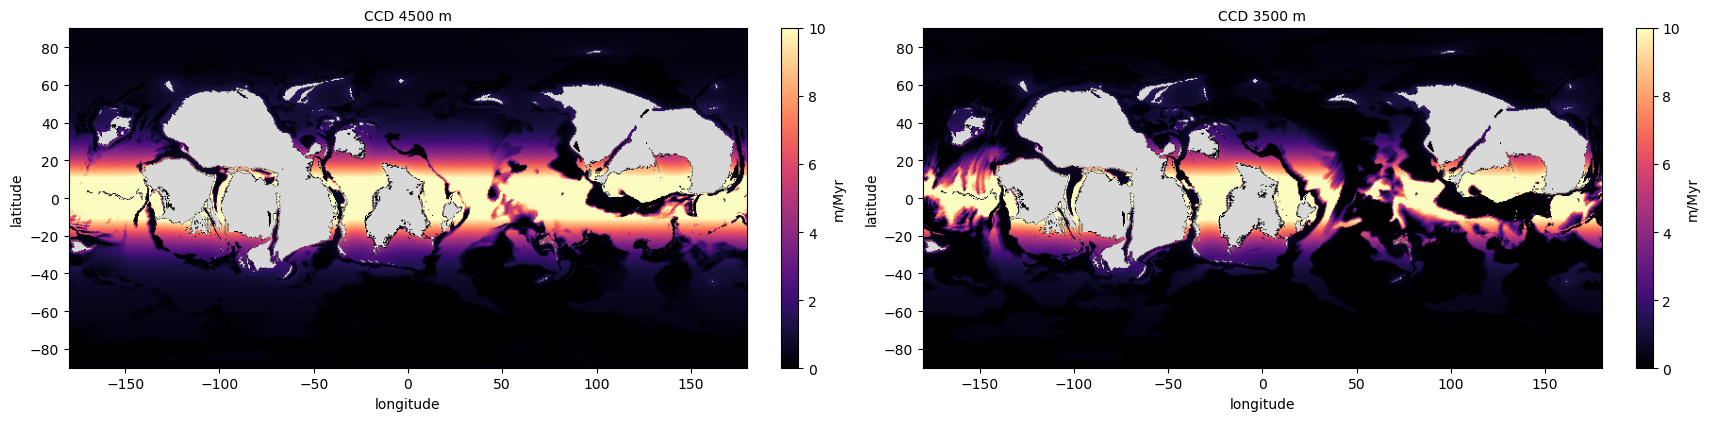

In [4]:
G.compare(['sim_carb', 'sim_ccd_shallow'], ['CCD 4500 m', 'CCD 3500 m']);

## Waves and coastal erosion (`input-waves.yml`)

The global wind belts with a 500 km fetch: open water carries the full wave
energy, the coasts in the lee of Pangea and inside the Tethys gulfs are
sheltered. The reef builders grow less there (`wave` response: 0.27 million
km3 of framework against 0.28), but coastal erosion abrades the exposed
shallow water and low coasts (0.15 million km3 over the run), reopening
space where the platform factories grow again and moving the eroded reef as
carbonate sand: the benthic carbonate ends 11 % higher than in the
reference.

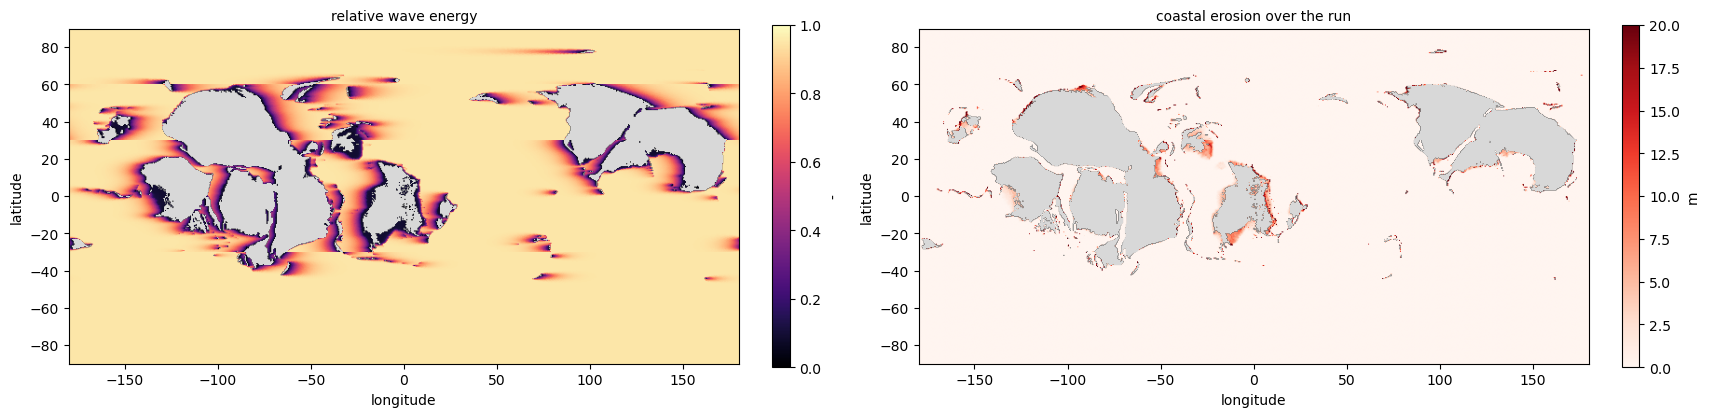

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.4), constrained_layout=True)
lon, lat, g = G.load('sim_waves', G.steps('sim_waves')[-1], ('elev', 'waveE', 'coastEro'))
land = g['elev'] >= 0.0
G.worldmap(lon, lat, g['waveE'], ax=ax[0], title='relative wave energy', cmap='magma',
           label='-', land=land, vmin=0, vmax=1)
G.worldmap(lon, lat, g['coastEro'], ax=ax[1], title='coastal erosion over the run',
           cmap='Reds', label='m', land=land, vmin=0, vmax=20);

## Coupling with the geochemistry (`input-geochem.yml`)

The weathering of the continents (three climate provinces, groundwater and
duricrust of `continental_geochem`) delivers dissolved carbonate to the
ocean, where it accumulates in a reservoir. The carbonate the factories and
the pelagic rain bury each step cannot exceed that reservoir times the
yield (`carbonate_supply`), and what is buried is drawn from it. With
`yield: 20` the burial is limited: scaled by 0.62 to 1.00 (0.80 on
average); the reservoir grows from 6.6e12 to 8.4e12 units, as the supply
exceeds the burial in the later steps. The benthic carbonate falls by 6 %
and the pelagic by 19 %. The `solute` response also favours the reef
builders near the large rivers.

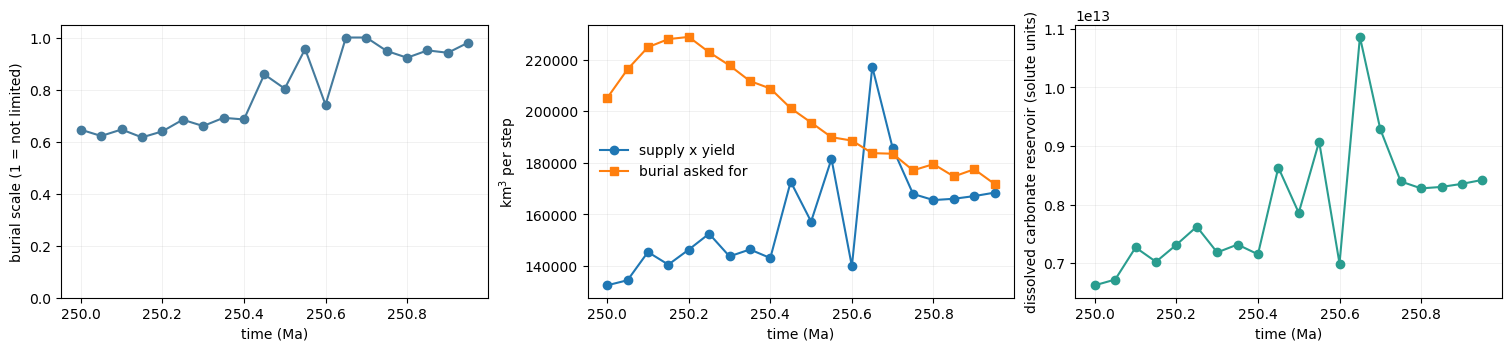

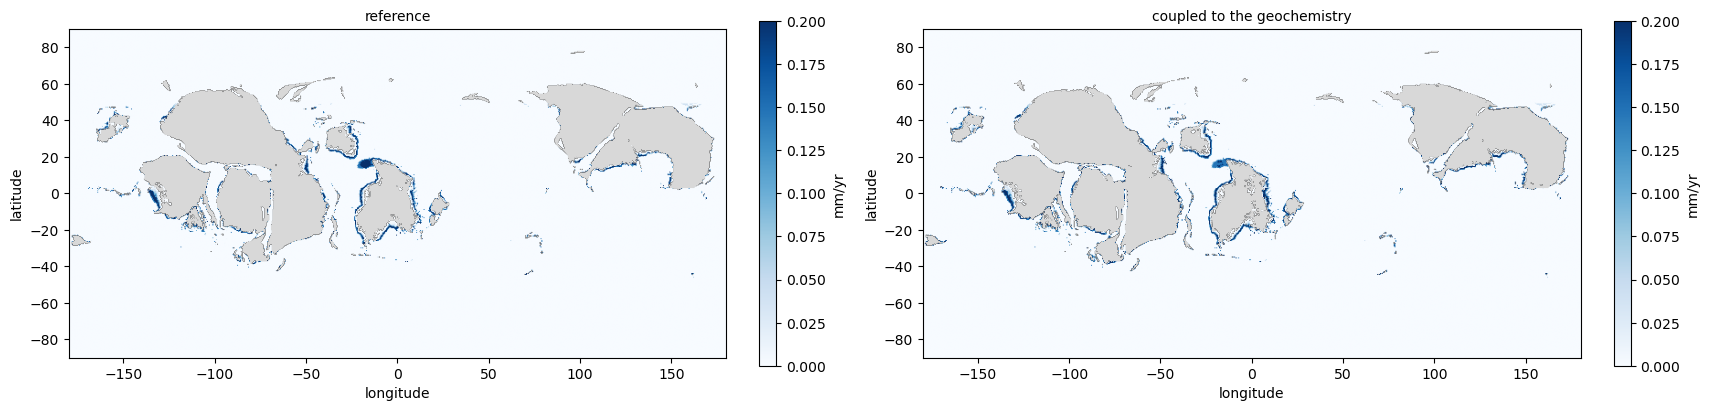

In [6]:
G.supply('geochem')
G.compare(['sim_carb', 'sim_geochem'], ['reference', 'coupled to the geochemistry'],
          key='carbProd', scale=1e3, label='mm/yr', vmax=0.2, cmap='Blues');

## Carbonate budgets

Over the run, per experiment.

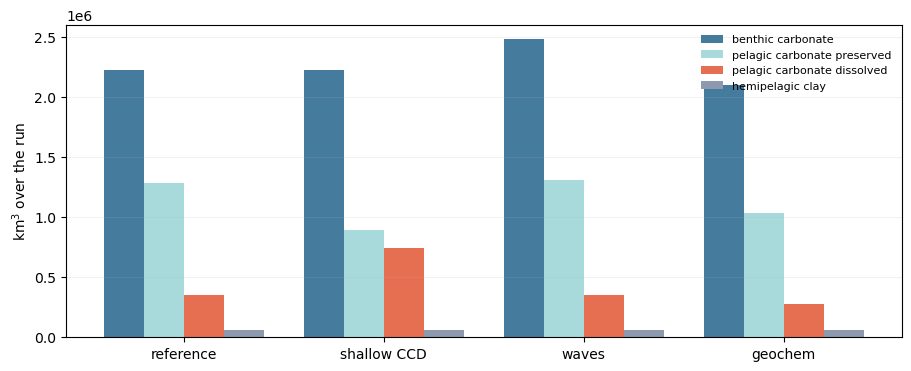

In [7]:
G.budget(['carb', 'ccd_shallow', 'waves', 'geochem'],
         ['reference', 'shallow CCD', 'waves', 'geochem']);

# Post-processing analyses and exports

## Carbonate by latitude

Carbonate deposited during the run (benthic and pelagic, from the
stratigraphy, ocean mean) and the pelagic deposition rate, averaged in 5
degree latitude bands. The carbonate follows the warm belt (the temperature
windows of the tropical factories and the tropical pelagic production); the
shallow CCD and the supply limit lower it, the coastal erosion raises it.

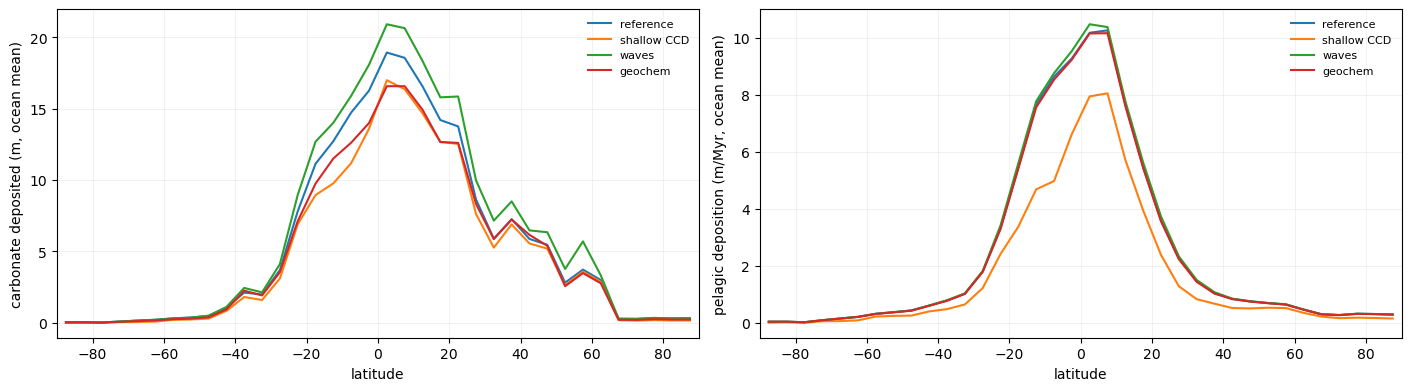

In [8]:
G.zonal(['sim_carb', 'sim_ccd_shallow', 'sim_waves', 'sim_geochem'], ['reference', 'shallow CCD', 'waves', 'geochem']);

Carbonate deposited in each climate belt (thousand km3, compacted, from the
stratigraphy): most of it in the tropics in every run.

In [9]:
G.belts(['sim_carb', 'sim_ccd_shallow', 'sim_waves', 'sim_geochem'], ['reference', 'shallow CCD', 'waves', 'geochem'])

run,reference,shallow CCD,waves,geochem
belt,,,,
tropics,2558522.0,2230326.0,2720107.0,2213040.0
subtropics,500465.0,446510.0,541113.0,482711.0
temperate,227478.0,208061.0,275472.0,220017.0
polar,43091.0,36026.0,46562.0,37937.0


## Carbonate share of the deposits

The carbonate share of what was deposited during the run (reference):
carbonate dominates the tropical shelves and the open ocean above the CCD,
river sediment the deltas and the margins of the large catchments.

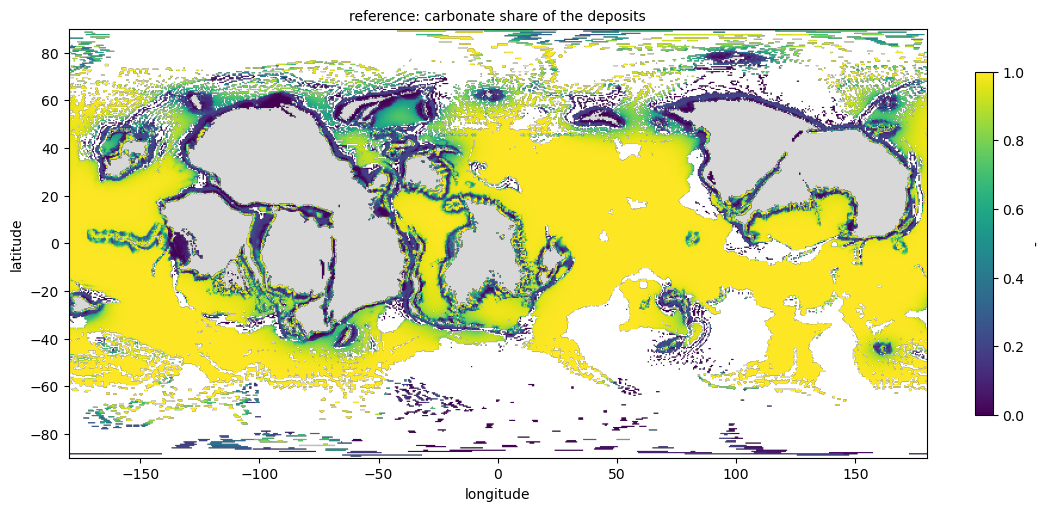

In [10]:
G.carbonate_share('sim_carb', 'reference: carbonate share of the deposits');

## A stratigraphic section

Across isolated carbonate platforms of the open Panthalassa ocean, along
2.4 degrees N from 160 to 139 degrees W, far from the continents. Coloured by
lithology (river sand yellow, river mud grey, carbonate sand light blue,
carbonate mud dark blue, reef pink), drawn twice: at true elevation from
the base of the model to the sea surface (top), and flattened on the base of
the deposits of the run (bottom), since 1 Myr leaves tens of metres of
sediment on kilometres of relief. Two platforms on oceanic highs (160-155 and
145-139 W) are capped by reef and carbonate sand; the 3 km deep basin
between them collects carbonate mud (pelagic rain above the CCD and mud shed
from the platforms) around sand bodies eroded from the islands.

The functions work on the global mesh in longitude and latitude
(`gospl.analyse.stratasection`).

**Caveat.** This example lowers the continental erosion of `continental_flux` five times (`spl: K: 1.e-6`); it is still about twice the present-day flux, and the river sediment piles up in the deep water off the large rivers (see the README).

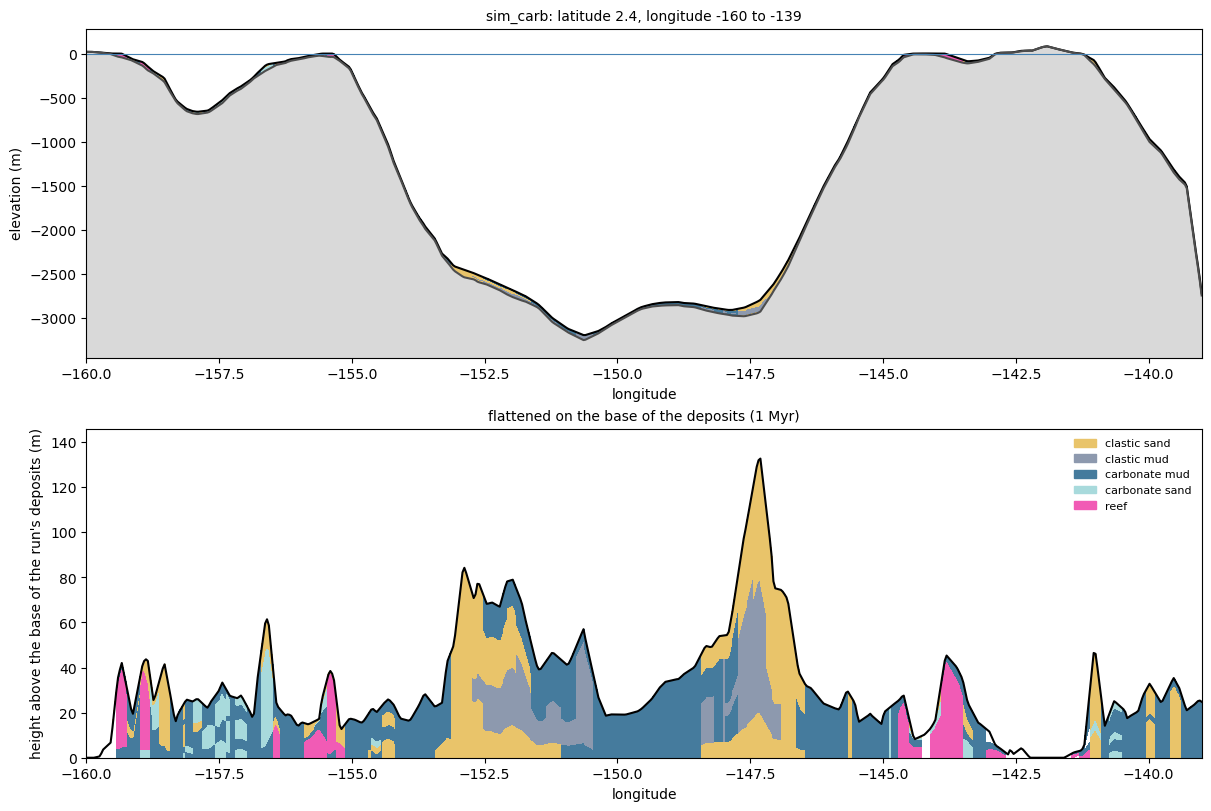

In [11]:
G.section('sim_carb', 2.4, (-160, -139));

## Exports

**A regular grid (NetCDF)** of the last output (fields, basins, chi) for
GMT, PyGMT, QGIS or ArcGIS, with `gospl.analyse.gridexport` (the command
line `gospl-grid` does the same):

In [12]:
import os
os.makedirs('results', exist_ok=True)
ds = G.export_grid('sim_carb', 'results/carb_final.nc', spacing=0.5)
ds

<xarray.Dataset> Size: 41MB
Dimensions:        (lat: 359, lon: 720)
Coordinates:
  * lat            (lat) float64 3kB -89.45 -88.95 -88.45 ... 88.55 89.05 89.55
  * lon            (lon) float64 6kB -180.0 -179.5 -179.0 ... 178.5 179.0 179.5
Data variables: (12/21)
    sea_level      float64 8B ...
    EDrate         (lat, lon) float64 2MB ...
    FA             (lat, lon) float64 2MB ...
    carbProd       (lat, lon) float64 2MB ...
    carbSedRate    (lat, lon) float64 2MB ...
    elev           (lat, lon) float64 2MB ...
    ...             ...
    waterFill      (lat, lon) float64 2MB ...
    drainage_area  (lat, lon) float64 2MB ...
    basin          (lat, lon) float64 2MB ...
    chi            (lat, lon) float64 2MB ...
    flowdist       (lat, lon) float64 2MB ...
    filled         (lat, lon) float64 2MB ...
Attributes:
    Conventions:  CF-1.7
    sea_level:    0.0

**The 3-D stratigraphy for ParaView**: a volume of prisms with the fraction
of every lithology, the dominant one and the carbonate share per layer
(see the README of `mixed_carbonate_clastic` for how to use it in ParaView).
Only the last output here (the time series is large on this mesh):

```bash
mpirun -np 8 gospl-strata-volume --h5dir sim_carb/h5 --outdir sim_carb/strata \
    --field lithologies --tout 1.e5 --tstart 250.e6 --steps 10
```

**Per-basin river delivery**: `gospl-grid` (above) writes the basins; the
outlet discharge and sediment load of every basin can then be extracted with
`gospl-catchment` (see the `continental_geochem` README for the commands).